# 📊 Task 3: Mall Customers Data Visualization Suite

This notebook presents a comprehensive visual analysis of the **Mall Customers** dataset. We focus on transforming raw data into high-quality visual stories, identifying key customer segments, and delivering actionable business insights using **Matplotlib** and **Seaborn**.

## Objectives:
1. **Demographic Analysis**: Understand customer distributions by Age, Gender, and Annual Income.
2. **Behavioral Analysis**: Study the relationship between Income, Age, and Spending Score.
3. **Customer Segmentation**: Use K-Means clustering to discover natural customer segments and visualize them cleanly.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import os

# Create output folder for assets
os.makedirs('assets', exist_ok=True)

# Set high-quality plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11

# Custom color palette (premium corporate colors)
palette = ["#1A365D", "#D69E2E", "#2B6CB0", "#E53E3E", "#319795"]
sns.set_palette(palette)
print("Environment and style setup complete!")


Environment and style setup complete!


## 📁 Load Dataset

In [2]:
# Load the dataset
df = pd.read_csv('Mall_Customers.csv')
print(f"Dataset shape: {df.shape}")
df.head()


Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 👥 1. Demographic Visualizations
Let's explore the gender split, age distribution, and income distribution of our customer base.


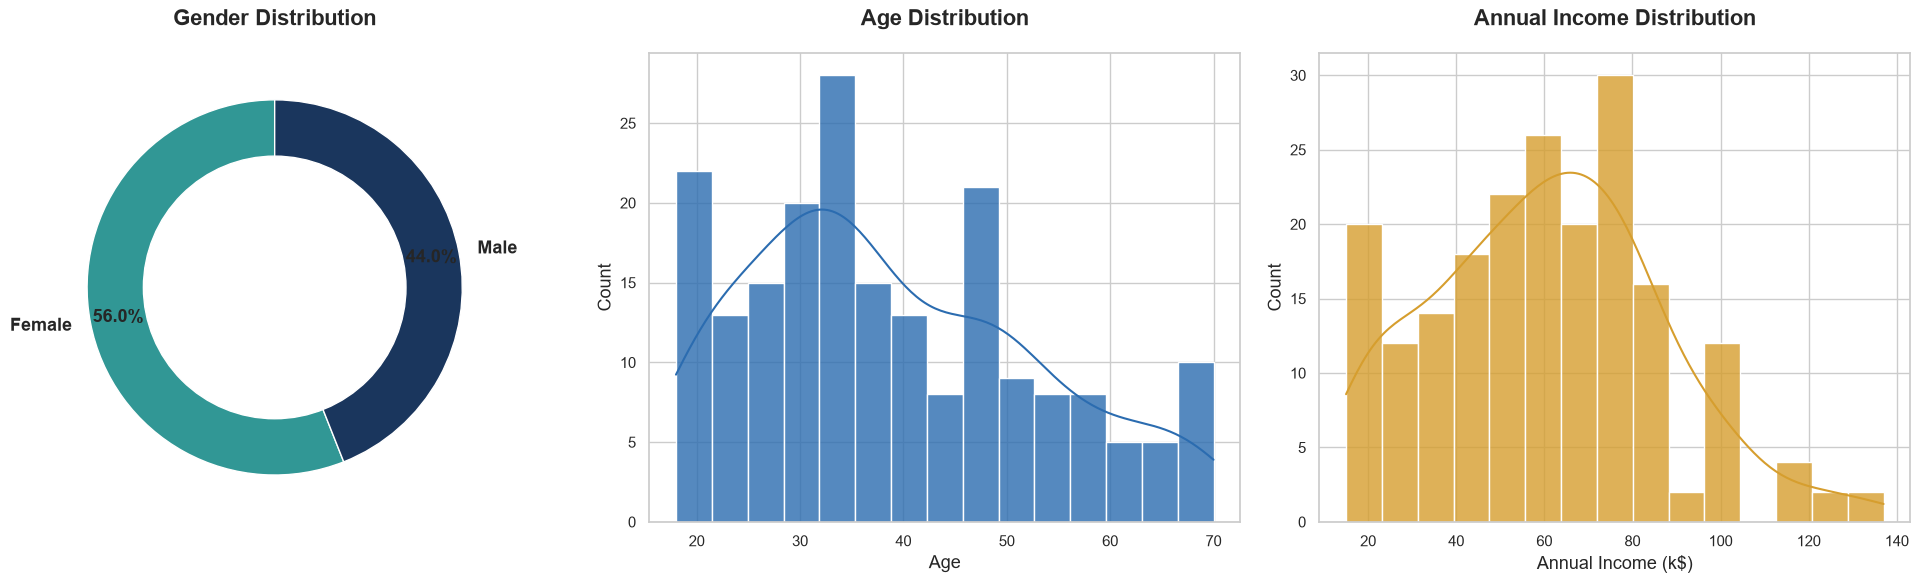

In [3]:
# Set up a grid of demographic plots
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Gender Distribution (Donut Chart)
gender_counts = df['Gender'].value_counts()
axes[0].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', 
        startangle=90, colors=['#319795', '#1A365D'], pctdistance=0.85,
        textprops={'fontsize': 13, 'weight': 'bold'})
# Draw white circle in center to make it a donut chart
centre_circle = plt.Circle((0,0),0.70,fc='white')
axes[0].add_artist(centre_circle)
axes[0].set_title('Gender Distribution', fontsize=16, weight='bold', pad=20)

# 2. Age Distribution (Density + Histogram)
sns.histplot(df['Age'], bins=15, kde=True, ax=axes[1], color='#2B6CB0', edgecolor='white', alpha=0.8)
axes[1].set_title('Age Distribution', fontsize=16, weight='bold', pad=20)
axes[1].set_xlabel('Age', fontsize=13)
axes[1].set_ylabel('Count', fontsize=13)

# 3. Income Distribution
sns.histplot(df['Annual Income (k$)'], bins=15, kde=True, ax=axes[2], color='#D69E2E', edgecolor='white', alpha=0.8)
axes[2].set_title('Annual Income Distribution', fontsize=16, weight='bold', pad=20)
axes[2].set_xlabel('Annual Income (k$)', fontsize=13)
axes[2].set_ylabel('Count', fontsize=13)

plt.tight_layout()
plt.savefig('assets/demographics.png', dpi=300)
plt.show()


## 💸 2. Income vs. Spending Score Relationship
Let's see how annual income maps against the customer's spending score to locate natural clusters.


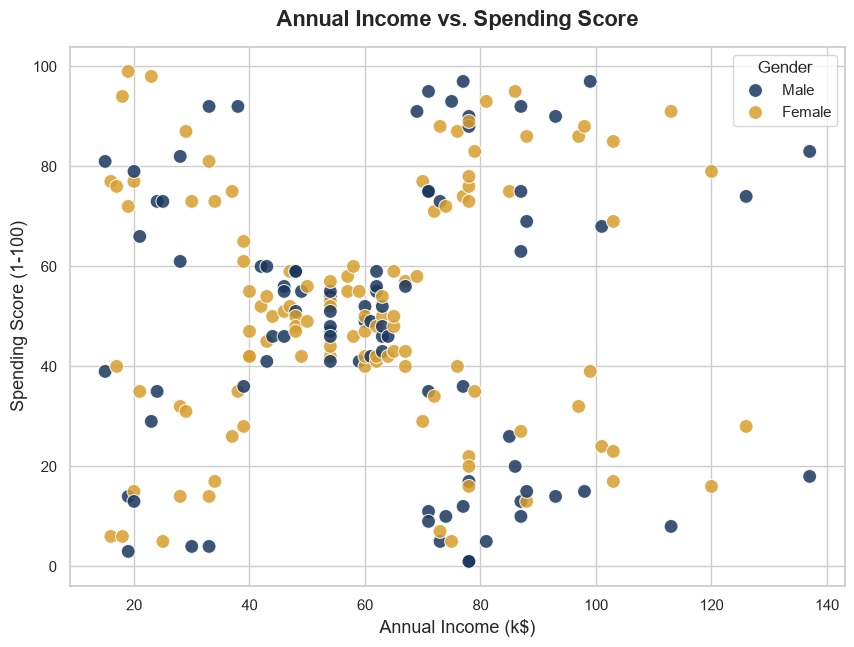

In [4]:
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    hue='Gender', 
    palette=['#1A365D', '#D69E2E'],
    s=100, 
    alpha=0.85, 
    edgecolor='w'
)
plt.title('Annual Income vs. Spending Score', fontsize=16, weight='bold', pad=15)
plt.xlabel('Annual Income (k$)', fontsize=13)
plt.ylabel('Spending Score (1-100)', fontsize=13)
plt.legend(title='Gender', frameon=True)
plt.savefig('assets/income_vs_spending.png', dpi=300)
plt.show()


## ⏳ 3. Age vs. Spending Score Relationship
Is spending score influenced by the customer's age? Let's check with a scatter plot and joint kernel density estimate.


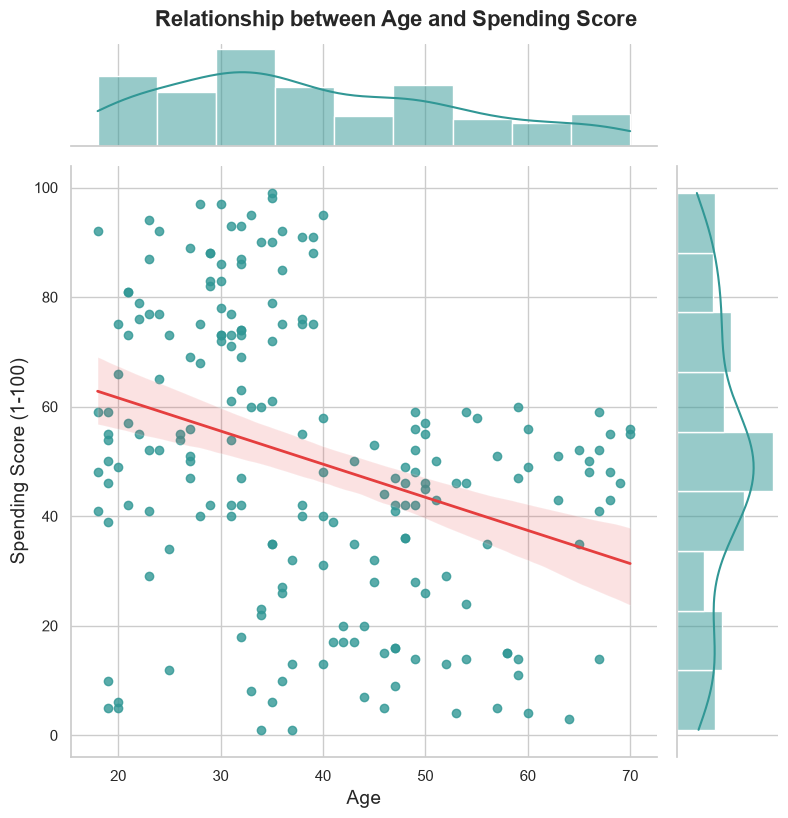

In [5]:
# Joint plot showing distribution & scatter with regression line
g = sns.jointplot(
    data=df, 
    x='Age', 
    y='Spending Score (1-100)', 
    kind='reg',
    color='#319795',
    height=8,
    joint_kws={'line_kws':{'color':'#E53E3E', 'linewidth': 2}}
)
g.fig.suptitle('Relationship between Age and Spending Score', weight='bold', y=1.02, fontsize=16)
plt.savefig('assets/age_vs_spending.png', dpi=300)
plt.show()


## ⚧ 4. Gender Differences in Spending & Income
Let's see if male or female customers have higher income or spending scores on average.


C:\Users\Amine\AppData\Local\Temp\ipykernel_5772\4214854841.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Gender', y='Annual Income (k$)', ax=axes[0], palette=['#1A365D', '#D69E2E'], inner="quartile")
C:\Users\Amine\AppData\Local\Temp\ipykernel_5772\4214854841.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Gender', y='Spending Score (1-100)', ax=axes[1], palette=['#1A365D', '#D69E2E'], inner="quartile")


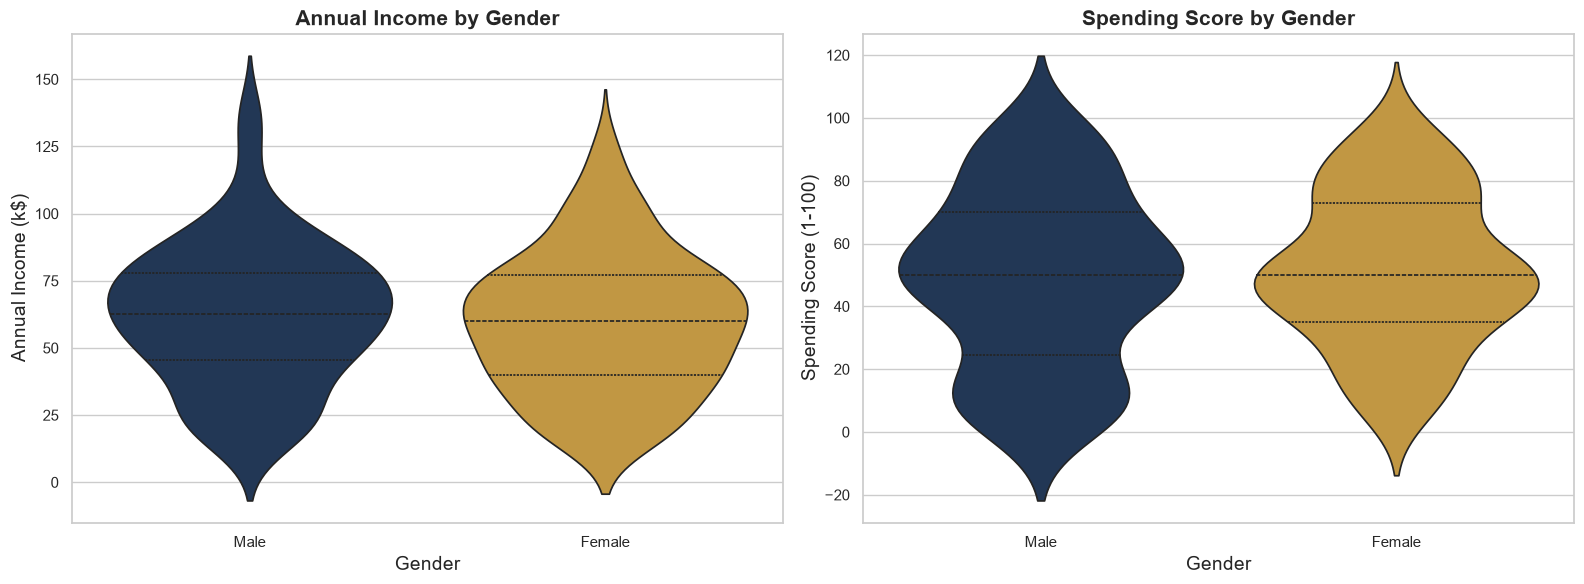

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Income by Gender
sns.violinplot(data=df, x='Gender', y='Annual Income (k$)', ax=axes[0], palette=['#1A365D', '#D69E2E'], inner="quartile")
axes[0].set_title('Annual Income by Gender', fontsize=15, weight='bold')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Annual Income (k$)')

# Spending Score by Gender
sns.violinplot(data=df, x='Gender', y='Spending Score (1-100)', ax=axes[1], palette=['#1A365D', '#D69E2E'], inner="quartile")
axes[1].set_title('Spending Score by Gender', fontsize=15, weight='bold')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.savefig('assets/gender_comparisons.png', dpi=300)
plt.show()


## 🏷️ 5. Customer Segmentation using K-Means Clustering
Let's use the Elbow method and Silhouette score to determine the optimal number of clusters for customer segmentation based on **Annual Income** and **Spending Score**.


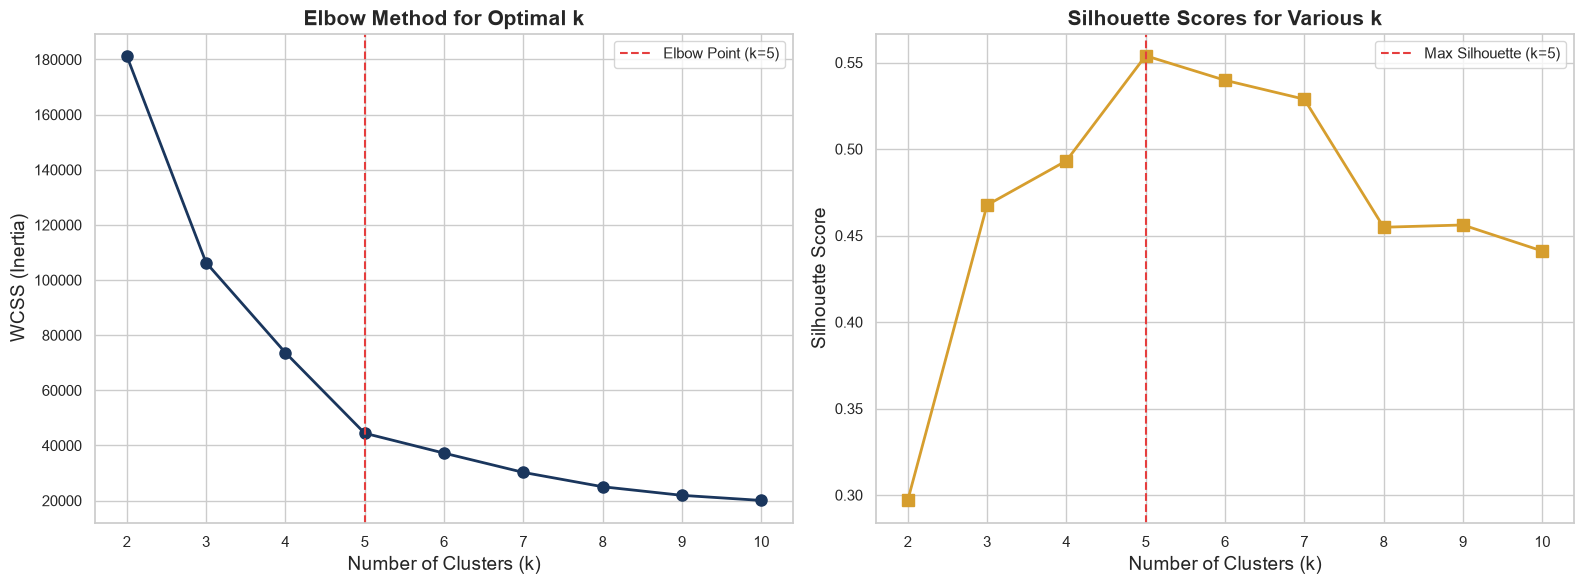

In [7]:
# Extract features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# Elbow Method
wcss = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X, kmeans.labels_))

# Plot Elbow and Silhouette scores side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(range(2, 11), wcss, marker='o', color='#1A365D', linewidth=2, markersize=8)
axes[0].axvline(5, color='#E53E3E', linestyle='--', label='Elbow Point (k=5)')
axes[0].set_title('Elbow Method for Optimal k', fontsize=15, weight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('WCSS (Inertia)')
axes[0].legend()

axes[1].plot(k_range, silhouette_scores, marker='s', color='#D69E2E', linewidth=2, markersize=8)
axes[1].axvline(5, color='#E53E3E', linestyle='--', label='Max Silhouette (k=5)')
axes[1].set_title('Silhouette Scores for Various k', fontsize=15, weight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()

plt.tight_layout()
plt.savefig('assets/kmeans_evaluation.png', dpi=300)
plt.show()


## 🎯 6. Visualizing Customer Segments (k=5)
We have selected $k=5$ as the optimal number of clusters. Let's fit the K-Means model, name each segment based on characteristics, and plot them.


Centroids coordinates (Income, Spending):
Cluster 0: Income = 55.3k$, Spending Score = 49.5
Cluster 1: Income = 86.5k$, Spending Score = 82.1
Cluster 2: Income = 25.7k$, Spending Score = 79.4
Cluster 3: Income = 88.2k$, Spending Score = 17.1
Cluster 4: Income = 26.3k$, Spending Score = 20.9


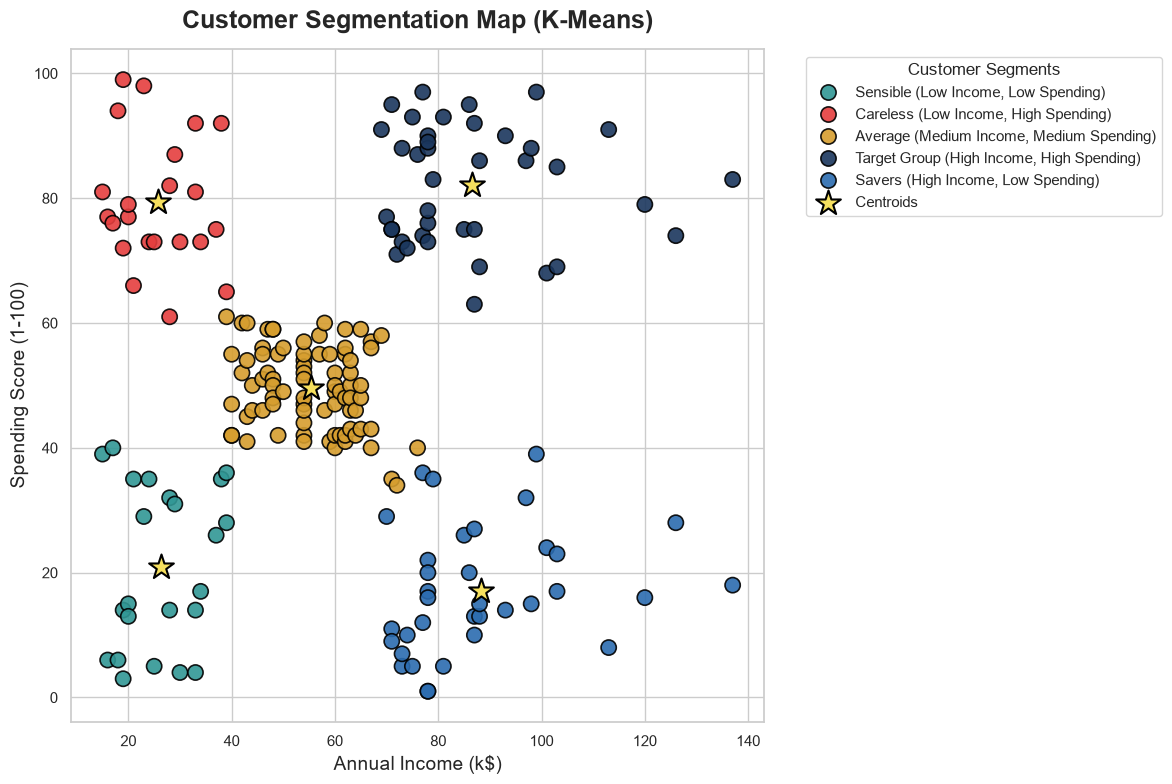

In [8]:
# Fit KMeans with k=5
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X)

# Name the clusters based on centroids
centroids = kmeans.cluster_centers_
print("Centroids coordinates (Income, Spending):")
for i, c in enumerate(centroids):
    print(f"Cluster {i}: Income = {c[0]:.1f}k$, Spending Score = {c[1]:.1f}")

# Persona definitions
cluster_labels = {}
for i in range(5):
    inc, sp = centroids[i]
    if inc < 40 and sp > 60:
        cluster_labels[i] = "Careless (Low Income, High Spending)"
    elif inc < 40 and sp < 40:
        cluster_labels[i] = "Sensible (Low Income, Low Spending)"
    elif inc > 70 and sp > 60:
        cluster_labels[i] = "Target Group (High Income, High Spending)"
    elif inc > 70 and sp < 40:
        cluster_labels[i] = "Savers (High Income, Low Spending)"
    else:
        cluster_labels[i] = "Average (Medium Income, Medium Spending)"

df['Segment'] = df['Cluster'].map(cluster_labels)

# Plotting the segment scatter plot
plt.figure(figsize=(12, 8))
# Setup custom color map
colors = ["#319795", "#E53E3E", "#D69E2E", "#1A365D", "#2B6CB0"]
sns.scatterplot(
    data=df, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    hue='Segment', 
    palette=colors,
    s=120, 
    alpha=0.9, 
    edgecolor='black',
    linewidth=1.2
)

# Plot Centroids
plt.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    s=350, 
    c='#F6E05E', 
    marker='*', 
    edgecolor='black', 
    linewidth=1.5, 
    label='Centroids'
)

plt.title('Customer Segmentation Map (K-Means)', fontsize=18, weight='bold', pad=15)
plt.xlabel('Annual Income (k$)', fontsize=14)
plt.ylabel('Spending Score (1-100)', fontsize=14)
plt.legend(title='Customer Segments', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig('assets/customer_segments_2d.png', dpi=300, bbox_inches='tight')
plt.show()


## 💡 Summary of Business Insights
Based on our visual analysis, we identified **5 distinct customer groups**:

1. **Target Group (High Income, High Spending)**: Ideal targets for luxury promotions, new arrivals, and premium loyalty clubs.
2. **Savers (High Income, Low Spending)**: Customers with high purchasing power but low spending. They could be targeted with quality/value-focused campaigns or premium credit card offerings.
3. **Careless (Low Income, High Spending)**: Customers who spend heavily despite lower income. They might respond well to sales, installment plans, and discount events.
4. **Sensible (Low Income, Low Spending)**: Cautious buyers who focus on essentials. Best reached via budget-friendly collections and coupon codes.
5. **Average (Medium Income, Medium Spending)**: The core customer base that responds to standard seasonal promotions.
